# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 19   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 19: Birman, Ragdoll, great_pyrenees, wheaten_terrier
  Скачиваю https://github.com/ykvnkm/computer-vision-course/releases/download/data-v1/variant_19.zip
  variant_19.zip: 84.4 МБ, готово.                              
  Распаковываю в /content/data/variant_19 ...
Готово: /content/data/variant_19 (807 изображений)
данные варианта: /content/data/variant_19
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 5.0.0 | numpy 2.1.3 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [3]:
# TODO: прочитайте variant.json и напечатайте его.
# Подсказка: путь собирайте от DATA_DIR, это объект Path, а не строка:
#   (DATA_DIR / "variant.json").read_text(encoding="utf-8") даёт текст файла,
#   json.loads(...) превращает текст в словарь.
import json
import pandas as pd

variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(variant_info)

# TODO: прочитайте labels.csv в DataFrame labels и покажите первые строки.
# Путь к файлу: DATA_DIR / "labels.csv"
labels = pd.read_csv(DATA_DIR / "labels.csv")
display(labels.head())


{'variant': 19, 'dataset_version': 'v1', 'source': 'release', 'breeds': ['Birman', 'Ragdoll', 'great_pyrenees', 'wheaten_terrier'], 'species': {'Birman': 'cat', 'Ragdoll': 'cat', 'great_pyrenees': 'dog', 'wheaten_terrier': 'dog'}, 'class_ids': {'Birman': 0, 'Ragdoll': 1, 'great_pyrenees': 2, 'wheaten_terrier': 3}, 'names_ru': {'Birman': 'бирманская кошка (священная бирма)', 'Ragdoll': 'рэгдолл', 'great_pyrenees': 'пиренейская горная собака', 'wheaten_terrier': 'ирландский мягкошёрстный пшеничный терьер'}, 'n_images': 807, 'n_boxes': 404, 'n_trimaps': 807, 'per_breed': {'Birman': {'images': 202, 'boxes': 102, 'trimaps': 202}, 'Ragdoll': {'images': 202, 'boxes': 101, 'trimaps': 202}, 'great_pyrenees': {'images': 201, 'boxes': 100, 'trimaps': 201}, 'wheaten_terrier': {'images': 202, 'boxes': 101, 'trimaps': 202}}, 'dataset': 'Oxford-IIIT Pet', 'dataset_url': 'https://www.robots.ox.ac.uk/~vgg/data/pets/', 'license': 'CC BY-SA 4.0', 'citation': 'O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V.

,filename,breed,species,class_id
0,Birman_1.jpg,Birman,cat,0
1,Birman_2.jpg,Birman,cat,0
2,Birman_3.jpg,Birman,cat,0
3,Birman_4.jpg,Birman,cat,0
4,Birman_5.jpg,Birman,cat,0


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [4]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

# TODO: прочитайте файл через cv2.imread(str(example_path)) в переменную bgr
# TODO: напечатайте type, shape, dtype, min, max и значение пикселя в центре кадра
#       bgr[bgr.shape[0] // 2, bgr.shape[1] // 2]
import cv2
import numpy as np

bgr = cv2.imread(str(example_path))

print("Type:", type(bgr))
print("Shape:", bgr.shape)
print("Dtype:", bgr.dtype)
print("Min:", bgr.min(), "Max:", bgr.max())

center_pixel = bgr[bgr.shape[0] // 2, bgr.shape[1] // 2]
print("Center pixel (BGR):", center_pixel)


Birman_176.jpg
Type: <class 'numpy.ndarray'>
Shape: (333, 500, 3)
Dtype: uint8
Min: 0 Max: 255
Center pixel (BGR): [ 6  3 12]


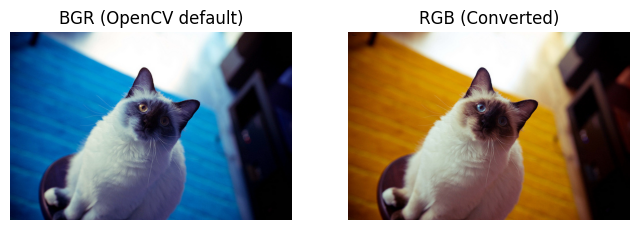

In [5]:
# TODO: переведите bgr в rgb через cv2.cvtColor(..., cv2.COLOR_BGR2RGB)
# TODO: покажите bgr и rgb рядом. Что случилось с цветами?
#   plt.subplot(1, 2, 1); plt.imshow(bgr)
#   plt.subplot(1, 2, 2); plt.imshow(rgb)
#   plt.show()
import matplotlib.pyplot as plt

rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(bgr)
plt.title("BGR (OpenCV default)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb)
plt.title("RGB (Converted)")
plt.axis("off")

plt.show()


Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [7]:
# TODO: получите gray, resized (224x224) и flipped, напечатайте их shape
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)

print("Gray shape:", gray.shape)
print("Resized shape:", resized.shape)
print("Flipped shape:", flipped.shape)

Gray shape: (333, 500)
Resized shape: (224, 224, 3)
Flipped shape: (333, 500, 3)


In [8]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


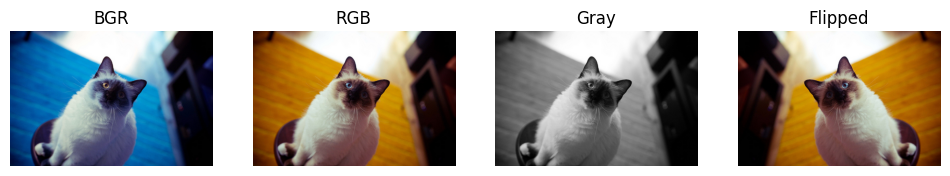

In [9]:
# TODO: 4 панели на одной фигуре: BGR как есть, RGB, серое, отражение
#   plt.figure(figsize=(12, 3))
#   plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
#   ... так же для rgb, gray (cmap="gray") и flipped
#   plt.savefig(RESULTS / "transforms.png", dpi=110)
import os

RESULTS.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 3))

plt.subplot(1, 4, 1)
plt.imshow(bgr)
plt.title("BGR")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(rgb)
plt.title("RGB")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(gray, cmap="gray")
plt.title("Gray")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(flipped)
plt.title("Flipped")
plt.axis("off")

plt.savefig(RESULTS / "transforms.png", dpi=110, bbox_inches="tight")
plt.show()


## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [11]:
from PIL import Image

label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue

    with Image.open(p) as im:
        pil_format = im.format
        mode = im.mode
        width, height = im.size

    xml_path = XML_DIR / (p.stem + ".xml")
    has_xml = xml_path.exists()

    breed = label_by_file.loc[p.name, "breed"]
    species = label_by_file.loc[p.name, "species"]

    rec = {
        "filename": p.name,
        "ext": p.suffix.lower(),
        "pil_format": pil_format,
        "mode": mode,
        "width": width,
        "height": height,
        "has_xml": has_xml,
        "breed": breed,
        "species": species,
    }
    rows.append(rec)

info = pd.DataFrame(rows)
display(info.head())

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Birman_1.jpg,.jpg,JPEG,RGB,375,500,False,Birman,cat
1,Birman_10.jpg,.jpg,JPEG,RGB,500,330,True,Birman,cat
2,Birman_100.jpg,.jpg,JPEG,RGB,500,334,True,Birman,cat
3,Birman_101.jpg,.jpg,JPEG,RGB,500,375,True,Birman,cat
4,Birman_102.jpg,.jpg,JPEG,RGB,332,500,True,Birman,cat


In [12]:
n_files = len(info)
n_breeds = info["breed"].nunique()
n_cats = (info["species"] == "cat").sum()
n_dogs = (info["species"] == "dog").sum()

min_w, med_w, max_w = int(info["width"].min()), int(info["width"].median()), int(info["width"].max())
min_h, med_h, max_h = int(info["height"].min()), int(info["height"].median()), int(info["height"].max())

non_rgb = (info["mode"] != "RGB").sum()

fake_jpeg = ((info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")).sum()

n_with_xml = info["has_xml"].sum()

summary = {
    "variant": VARIANT,
    "n_files": n_files,
    "n_breeds": n_breeds,
    "n_cats": n_cats,
    "n_dogs": n_dogs,
    "min_width": min_w,
    "med_width": med_w,
    "max_width": max_w,
    "min_height": min_h,
    "med_height": med_h,
    "max_height": max_h,
    "non_rgb": non_rgb,
    "fake_jpeg": fake_jpeg,
    "n_with_xml": n_with_xml,
}

summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
RESULTS.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(RESULTS / "summary.csv", index=False)
display(summary_df)

,metric,value
0,variant,19
1,n_files,807
2,n_breeds,4
3,n_cats,404
4,n_dogs,403
5,min_width,183
6,med_width,500
7,max_width,1024
8,min_height,194
9,med_height,375


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [13]:
# TODO: напечатайте файлы с mode != "RGB" и файлы с pil_format != "JPEG"
# mode != "RGB"
non_rgb_files = info[info["mode"] != "RGB"]["filename"].tolist()
print("Файлы не в режиме RGB:", non_rgb_files)

# pil_format != "JPEG"
fake_jpeg_files = info[(info["ext"] == ".jpg") & (info["pil_format"] != "JPEG")]["filename"].tolist()
print("Файлы с несовпадающим форматом:", fake_jpeg_files)

Файлы не в режиме RGB: []
Файлы с несовпадающим форматом: []


In [16]:
# TODO: сравните формы массивов для одного проблемного файла
if len(non_rgb_files) > 0:
    bad_filename = non_rgb_files[0]
elif len(fake_jpeg_files) > 0:
    bad_filename = fake_jpeg_files[0]
else:
    bad_filename = info["filename"].iloc[0]

bad_path = IMG_DIR / bad_filename

shape_default = cv2.imread(str(bad_path)).shape
shape_unchanged = cv2.imread(str(bad_path), cv2.IMREAD_UNCHANGED).shape

print(f"Файл для проверки: {bad_filename}")
print("cv2.imread(p).shape:", shape_default)
print("cv2.imread(p, cv2.IMREAD_UNCHANGED).shape:", shape_unchanged)

Файл для проверки: Birman_1.jpg
cv2.imread(p).shape: (500, 375, 3)
cv2.imread(p, cv2.IMREAD_UNCHANGED).shape: (500, 375, 3)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [17]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

# TODO: возьмите одно изображение с XML и напечатайте его боксы
# TODO: прочитайте его trimap: cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
#       и выведите np.unique(trimap)
import xml.etree.ElementTree as ET

# Находим первый файл, у которого есть XML-разметка
sample_row = info[info["has_xml"] == True].iloc[0]
sample_stem = Path(sample_row["filename"]).stem

# 1. Читаем и выводим боксы
sample_xml = XML_DIR / (sample_stem + ".xml")
boxes = read_boxes(sample_xml)
print("Файл:", sample_row["filename"])
print("Боксы головы (xmin, ymin, xmax, ymax):", boxes)

# 2. Читаем тримап и выводим уникальные значения (1 = животное, 2 = фон, 3 = граница)
sample_trimap_path = TRIMAP_DIR / (sample_stem + ".png")
if sample_trimap_path.exists():
    trimap = cv2.imread(str(sample_trimap_path), cv2.IMREAD_UNCHANGED)
    print("Уникальные значения в trimap (np.unique):", np.unique(trimap))

Файл: Birman_10.jpg
Боксы головы (xmin, ymin, xmax, ymax): [(45, 103, 194, 225)]
Уникальные значения в trimap (np.unique): [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

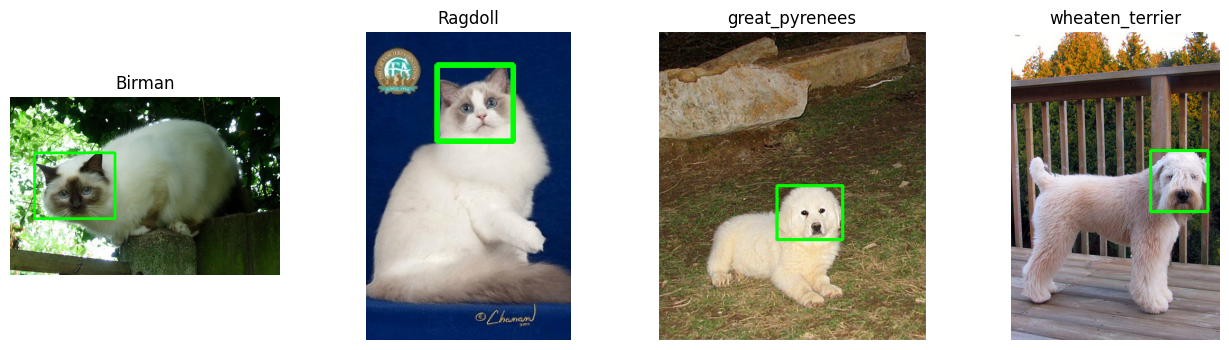

In [18]:
# TODO: для каждой породы возьмите одно фото с XML, нарисуйте бокс,
#       покажите все фото в один ряд через plt.subplot и сохраните в results/samples_grid.png
import matplotlib.pyplot as plt

# Берем уникальные породы из датасета
breeds = info["breed"].unique()
n_breeds = len(breeds)

plt.figure(figsize=(4 * n_breeds, 4))

for i, breed in enumerate(breeds):
    # Находим первое изображение с XML для текущей породы
    b_row = info[(info["breed"] == breed) & (info["has_xml"] == True)]
    if len(b_row) == 0:
        # Если вдруг с XML нет, берем любое
        b_row = info[info["breed"] == breed].iloc[0]
    else:
        b_row = b_row.iloc[0]

    fn = b_row["filename"]
    img_path = IMG_DIR / fn
    xml_path = XML_DIR / (Path(fn).stem + ".xml")

    # Читаем картинку и переводим в RGB для matplotlib
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Если есть XML, рисуем зеленый прямоугольник бокса головы
    if xml_path.exists():
        for box in read_boxes(xml_path):
            xmin, ymin, xmax, ymax = box
            # cv2.rectangle принимает координаты (x0, y0), (x1, y1), цвет BGR, толщину
            cv2.rectangle(img_rgb, (xmin, ymin), (xmax, ymax), (0, 255, 0), 3)

    # Выводим в сетку
    plt.subplot(1, n_breeds, i + 1)
    plt.imshow(img_rgb)
    plt.title(f"{breed}")
    plt.axis("off")

# Сохраняем сетку в results/samples_grid.png
RESULTS.mkdir(parents=True, exist_ok=True)
plt.savefig(RESULTS / "samples_grid.png", dpi=110, bbox_inches="tight")
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [19]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

    metric  value
   variant     19
   n_files    807
  n_breeds      4
    n_cats    404
    n_dogs    403
 min_width    183
 med_width    500
 max_width   1024
min_height    194
med_height    375
max_height    900
   non_rgb      0
 fake_jpeg      0
n_with_xml    404
не хватает: ничего, все 3 файла на месте


In [20]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>